In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py
from tqdm import tqdm
from scipy import sparse
from scipy.ndimage import gaussian_filter1d  

from darksirenpop.utilities.redshift_utils import _DL_INTERP
import astropy.units as u
from scipy.stats import truncnorm

from darksirenpop.utilities.utils import make_nice_plots
from darksirenpop.utilities.default_globals import *

make_nice_plots()

In [3]:
thresh = 44.5  # Luminosity threshold used to generate the posteriors in zpostfile

# Read catalogue and apply exactly the same selection used to generate the posteriors
df = pd.read_csv(QUAIA_PATH)
b = df["b"].to_numpy()
loglbol_corr = df["loglbol_corr"].to_numpy()
selection = ((b > 10) | (b < -10)) & (loglbol_corr >= thresh)
loglbol_corr_selected = loglbol_corr[selection]

# Gaia RP flux in erg/s/cm^2/Hz
ZP = 24.7479
C_NU = 3.298815E-33
rp_mag = df["phot_rp_mean_mag"].to_numpy()[selection]
log10_flux = -(rp_mag - ZP) / 2.5 + np.log10(C_NU) + 3


In [4]:
log_nu_max = np.log10(4*(10**14.588))

x = [14.586, 15.191]
y = [45.315, 45.692]
slope = (y[1] - y[0]) / (x[1] - x[0])

qz_selected = df["redshift_quaia"].to_numpy()[selection]
qz_err_selected = df["redshift_quaia_err"].to_numpy()[selection]

Nsamps = 1000
base = 14.588 + np.log10(4 * np.pi)
bolcor = truncnorm.rvs(loc=11.004, scale=3, size=Nsamps, a=(0 - 11.004) / 3, b=np.inf)

lowers = np.zeros_like(log10_flux)
uppers = np.zeros_like(log10_flux)
medians = np.zeros_like(log10_flux)
P_below_46p5 = np.zeros_like(log10_flux)
P_below_45p5 = np.zeros_like(log10_flux)
P_below_44p5 = np.zeros_like(log10_flux)
for i in tqdm( range(len(log10_flux)) ):
    zsamps = truncnorm.rvs(loc=qz_selected[i], scale=qz_err_selected[i], size=Nsamps, a=(0 - qz_selected[i]) / qz_err_selected[i], b=np.inf)
    # plt.hist(zsamps, bins=100)
    dlsamps = (_DL_INTERP(zsamps) * u.Mpc).to('cm').value
    log10_bollum = base + log10_flux[i] + 2 * np.log10(dlsamps) + (-1 * slope) * np.log10(1 + zsamps) + np.log10(bolcor)
    log10_bollum_corrected = 0.9994 * log10_bollum - 0.0433 * zsamps - 0.0124

    # shift = loglbol_corr_selected[i] - np.median(log10_bollum_corrected)
    # log10_bollum_corrected += shift   # Let median overlap with actual value used in paper

    q16 = np.quantile(log10_bollum_corrected, 0.16)
    q50 = np.quantile(log10_bollum_corrected, 0.50)
    q84 = np.quantile(log10_bollum_corrected, 0.84)

    lowers[i] = q50 - q16
    uppers[i] = q84 - q50
    medians[i] = q50

    P_below_46p5[i] = np.sum(log10_bollum_corrected < 46.5) / len(log10_bollum_corrected)
    P_below_45p5[i] = np.sum(log10_bollum_corrected < 45.5) / len(log10_bollum_corrected)
    P_below_44p5[i] = np.sum(log10_bollum_corrected < 44.5) / len(log10_bollum_corrected)

    # plt.figure()
    # plt.hist(log10_bollum, bins=100, histtype='step', density='True', linewidth=3, label='Orig)
    # plt.hist(log10_bollum_corrected, bins=100, histtype='step', density='True', linewidth=3, label='Corr')
    # plt.vlines([q16, q84], 0, 2, color='black')
    # plt.legend()
    # plt.show()

    # if i > 10000:
    #     break


100%|██████████| 1243143/1243143 [17:36<00:00, 1176.20it/s]


/home/lucas/Documents/PhD/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


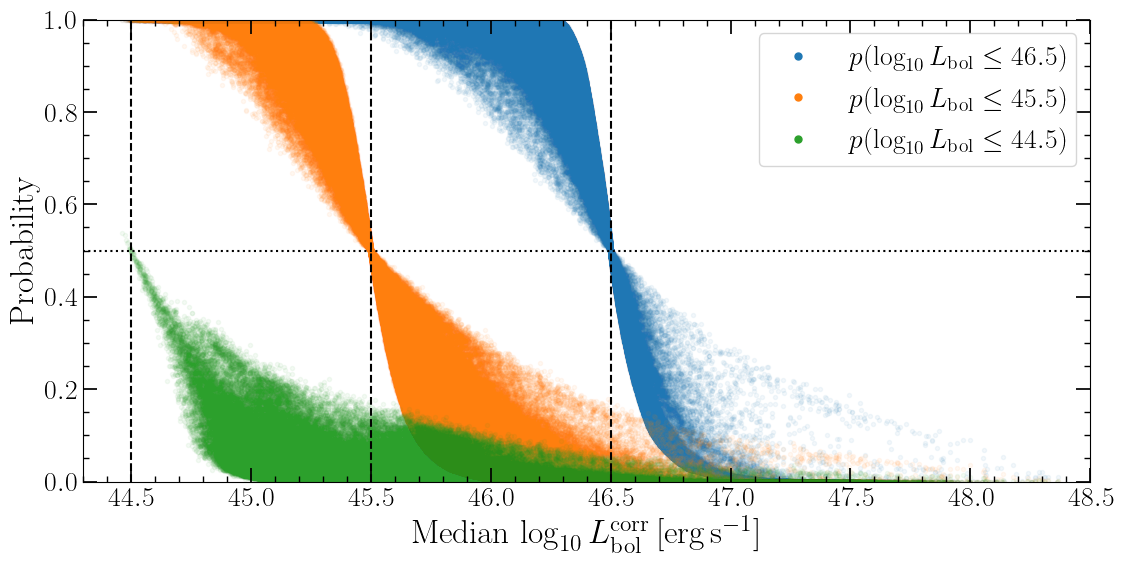

In [5]:
from matplotlib.lines import Line2D

plt.figure(figsize=(13,6))
plt.scatter(medians, P_below_46p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 46.5)$')
plt.scatter(medians, P_below_45p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 45.5)$')
plt.scatter(medians, P_below_44p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 44.5)$')

plt.vlines([44.5, 45.5, 46.5], 0, 1, color='black', linestyle='dashed')
plt.hlines(0.5, 44, 49, linestyle='dotted', color='black')

colors = ['C0', 'C1', 'C2']

handles = [
    Line2D([], [], marker='.', linestyle='None', color=c,
           markersize=10, alpha=1, label=label)
    for c, label in zip(colors, [
        r'$p(\log_{10} L_{\rm bol} \leq 46.5)$',
        r'$p(\log_{10} L_{\rm bol} \leq 45.5)$',
        r'$p(\log_{10} L_{\rm bol} \leq 44.5)$'
    ])
]

plt.legend(handles=handles)
plt.ylabel('Probability')
plt.xlabel(r'Median $\log_{10} L_{\rm bol}^{\rm corr} \, [\mathrm{erg\, s^{-1}}]$')
plt.xlim(44.3, 48.5)
plt.ylim(0, 1)
plt.show()


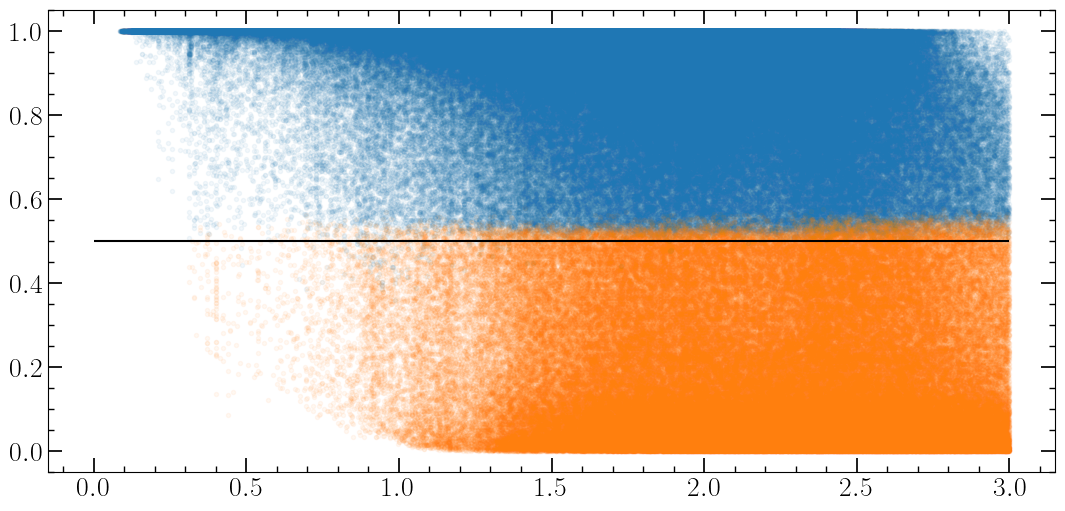

103
377


In [25]:
plt.figure(figsize=(13,6))
# plt.scatter(qz_selected, P_below_46p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 46.5)$')
plt.scatter(qz_selected[loglbol_corr_selected < 46.5], P_below_46p5[loglbol_corr_selected < 46.5], marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 46.5)$')
plt.scatter(qz_selected[loglbol_corr_selected > 46.5], P_below_46p5[loglbol_corr_selected > 46.5], marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 46.5)$')
plt.hlines(0.5, 0, 3, color='black')
# plt.scatter(qz_selected, P_below_45p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 45.5)$')
# plt.scatter(qz_selected, P_below_44p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 44.5)$')
plt.show()

print(np.sum(P_below_46p5[(loglbol_corr_selected < 46.5) & (qz_selected < 1.2)] < 0.5))
print(np.sum(P_below_46p5[(loglbol_corr_selected > 46.5) & (qz_selected < 1.2)] > 0.5))


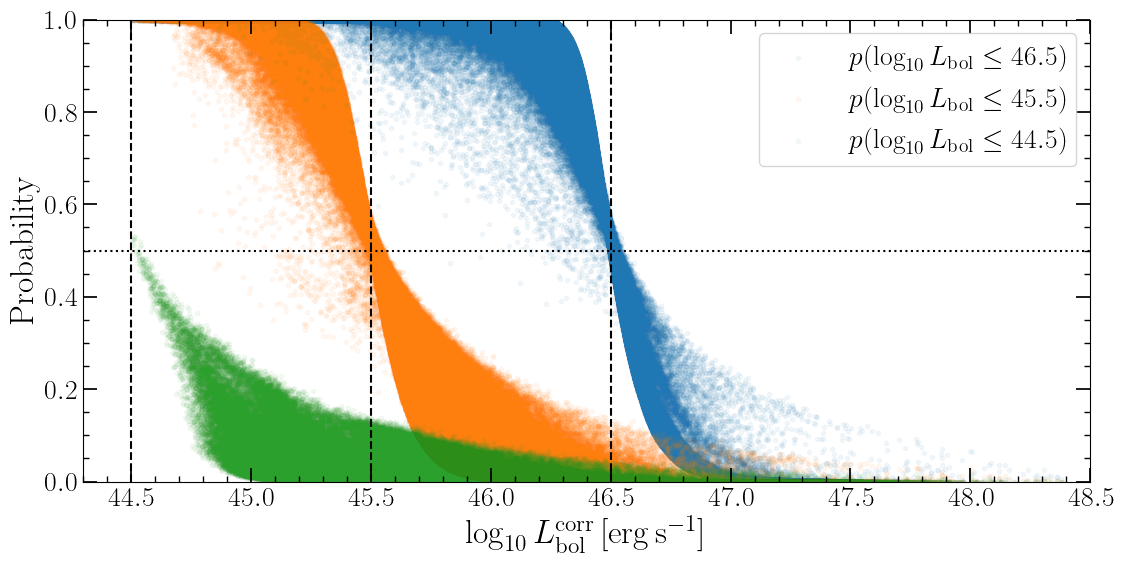

logL >= 46.5: N = 198381, but 37021 may be below.
logL >= 45.5: N = 1084496, but 64685 may be below.
logL >= 44.5: N = 1243143, but 6708 may be below.
logL < 46.5: N = 1044762, but 46782 may be above.
logL < 45.5: N = 158647, but 29232 may be above.
logL < 44.5: N = 0, not enough data below.
logL >= 46.5: -9762
logL >= 45.5: 35453


In [21]:
plt.figure(figsize=(13,6))
plt.scatter(loglbol_corr_selected, P_below_46p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 46.5)$')
plt.scatter(loglbol_corr_selected, P_below_45p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 45.5)$')
plt.scatter(loglbol_corr_selected, P_below_44p5, marker='.', alpha=0.05, label=r'$p(\log_{10} L_{\rm bol} \leq 44.5)$')
plt.vlines([44.5, 45.5, 46.5], 0, 1, color='black', linestyle='dashed')
plt.hlines(0.5, 44, 49, linestyle='dotted', color='black')
plt.ylabel('Probability')
plt.xlabel(r'$\log_{10} L_{\rm bol}^{\rm corr} \, [\mathrm{erg \, s^{-1}}]$')
plt.legend()
plt.xlim(44.3, 48.5)
plt.ylim(0, 1)
plt.show()

print(f'logL >= 46.5: N = {np.sum(loglbol_corr_selected >= 46.5)}, but {np.sum(P_below_46p5[loglbol_corr_selected >= 46.5]):.0f} may be below.')
print(f'logL >= 45.5: N = {np.sum(loglbol_corr_selected >= 45.5)}, but {np.sum(P_below_45p5[loglbol_corr_selected >= 45.5]):.0f} may be below.')
print(f'logL >= 44.5: N = {np.sum(loglbol_corr_selected >= 44.5)}, but {np.sum(P_below_44p5[loglbol_corr_selected >= 44.5]):.0f} may be below.')

print(f'logL < 46.5: N = {np.sum(loglbol_corr_selected < 46.5)}, but {np.sum(1 - P_below_46p5[loglbol_corr_selected < 46.5]):.0f} may be above.')
print(f'logL < 45.5: N = {np.sum(loglbol_corr_selected < 45.5)}, but {np.sum(1 - P_below_45p5[loglbol_corr_selected < 45.5]):.0f} may be above.')
print(f'logL < 44.5: N = {np.sum(loglbol_corr_selected < 44.5)}, not enough data below.')

print(f'logL >= 46.5: {np.sum(P_below_46p5[loglbol_corr_selected >= 46.5]) - np.sum(1 - P_below_46p5[loglbol_corr_selected < 46.5]):.0f}')
print(f'logL >= 45.5: {np.sum(P_below_45p5[loglbol_corr_selected >= 45.5]) - np.sum(1 - P_below_45p5[loglbol_corr_selected < 45.5]):.0f}')

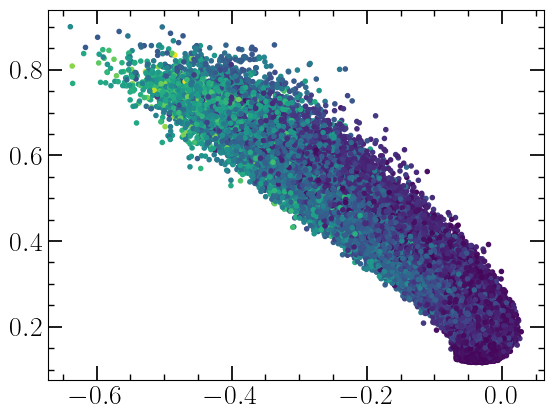

0.534712553024292 0.9246742542266844


/tmp/ipykernel_430079/3099825879.py:12: RuntimeWarning: invalid value encountered in log10
  log10_bollum = base + log10_flux[most_asymmetric] + 2 * np.log10(dlsamps) + (-1 * slope) * np.log10(1 + zsamps) + np.log10(bolcor)


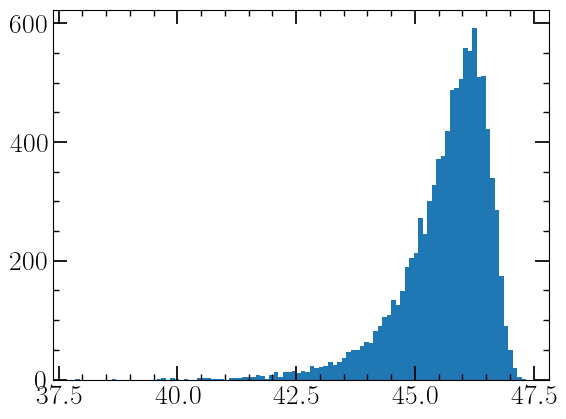

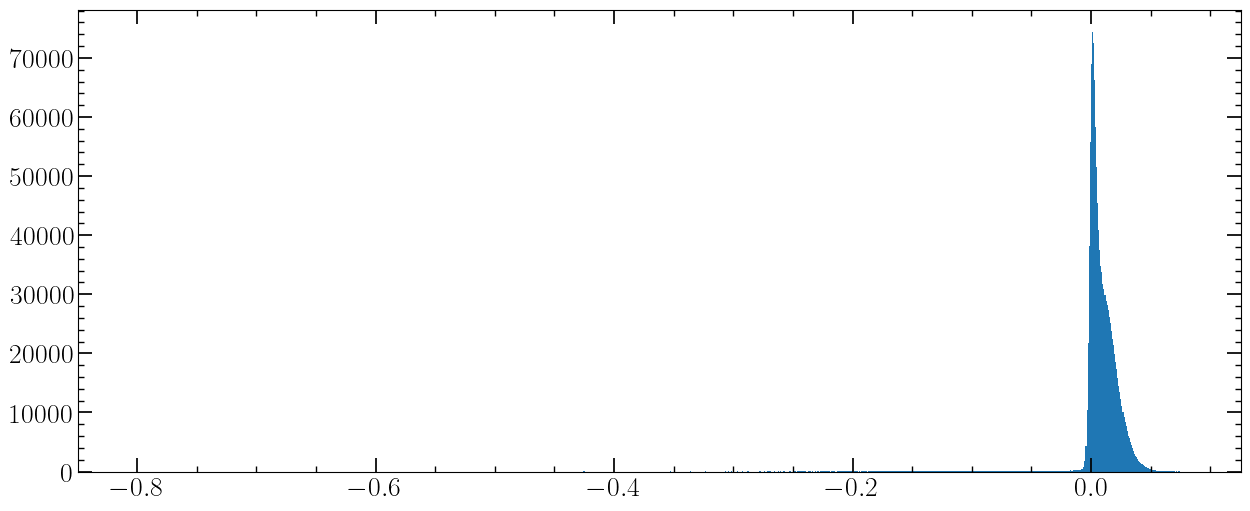

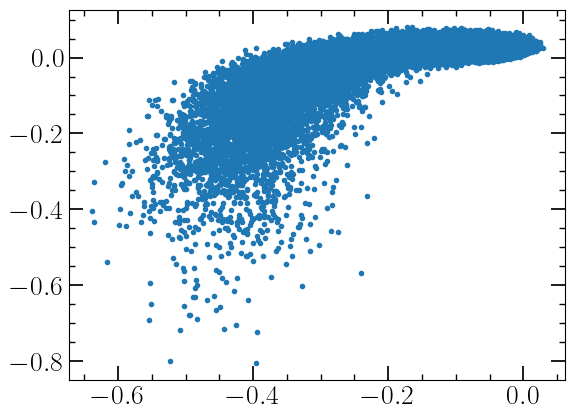

0.006783136584893157


In [16]:
# Check some skewness

plt.figure()
plt.scatter(uppers - lowers, (uppers + lowers) / 2, c=qz_err_selected, marker='.')
plt.show()

most_asymmetric = np.argmin(uppers - lowers)
print(qz_selected[most_asymmetric], qz_err_selected[most_asymmetric])
bolcor = np.random.normal(11.004, scale=3, size=Nsamps*10)
zsamps = truncnorm.rvs(loc=qz_selected[most_asymmetric], scale=qz_err_selected[most_asymmetric], size=Nsamps*10, a=(0 - qz_selected[most_asymmetric]) / qz_err_selected[most_asymmetric], b=np.inf)
dlsamps = (_DL_INTERP(zsamps) * u.Mpc).to('cm').value
log10_bollum = base + log10_flux[most_asymmetric] + 2 * np.log10(dlsamps) + (-1 * slope) * np.log10(1 + zsamps) + np.log10(bolcor)
plt.figure()
plt.hist(log10_bollum, bins=100)
plt.show()


plt.figure(figsize=(15,6))
plt.hist(loglbol_corr_selected - medians, bins=1000)
plt.show()

plt.figure()
plt.scatter(uppers - lowers, loglbol_corr_selected - medians, marker='.')
plt.show()
print(np.median(loglbol_corr_selected - medians))


0.14080764811629365 0.023812334621973713 0.20473788753485894


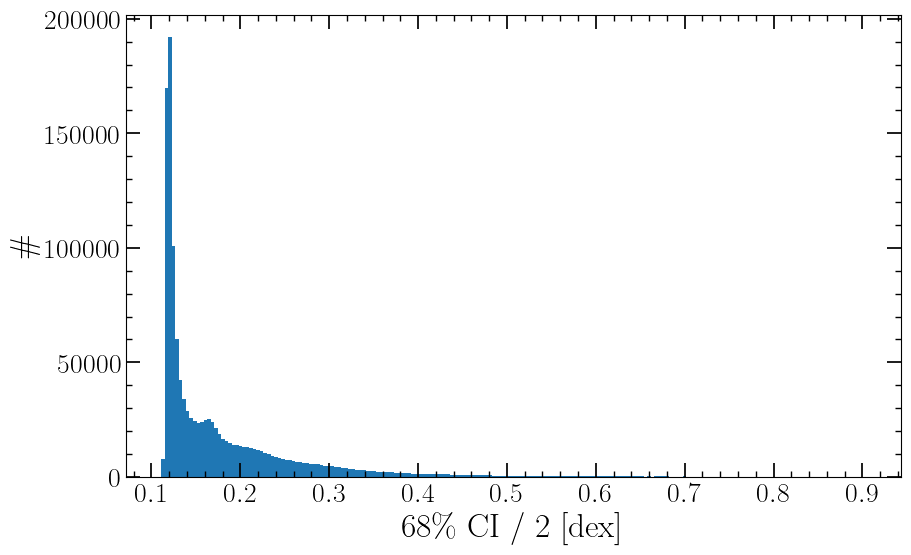

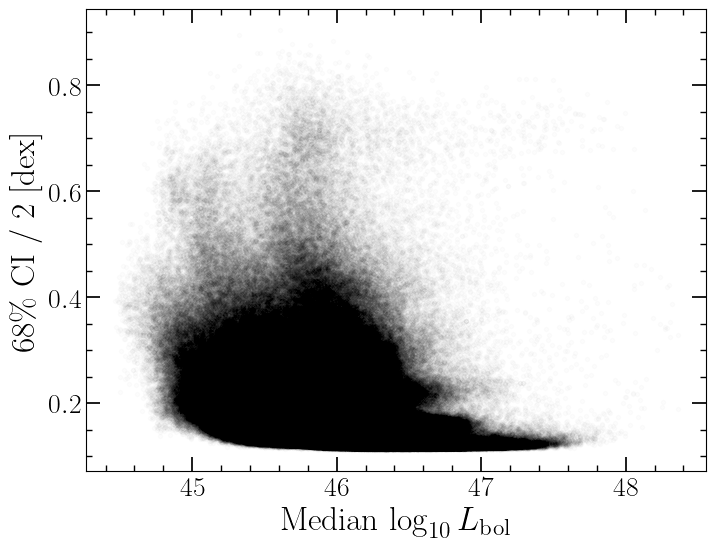

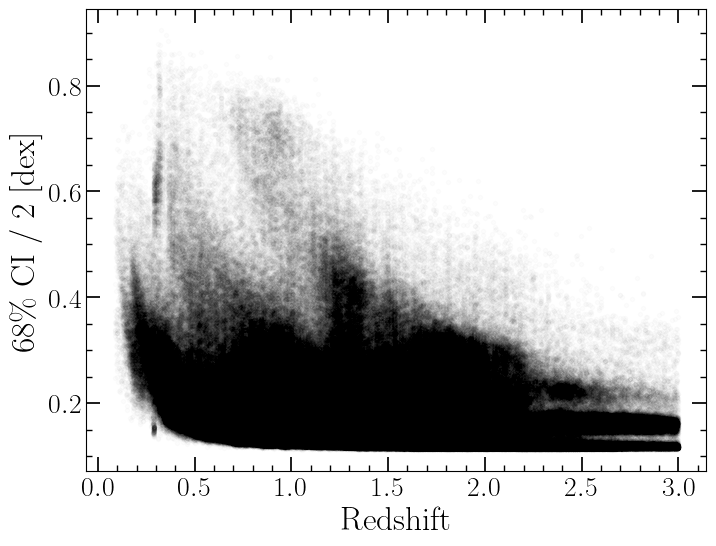

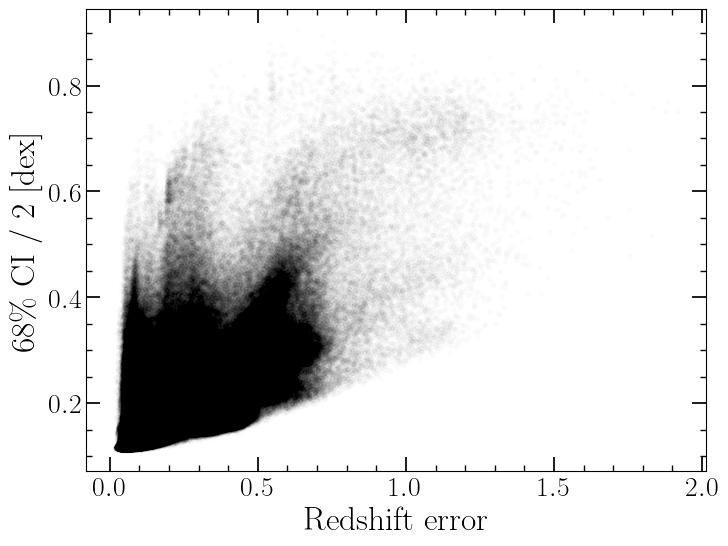

0.9039134480743769


In [28]:
half68error = (uppers + lowers) / 2
print(np.median(half68error), np.median(half68error) - np.quantile(half68error, 0.05), np.quantile(half68error, 0.95) - np.median(half68error))

plt.figure(figsize=(10,6))
plt.hist(half68error, bins=200)
# plt.semilogy()
plt.ylabel(r'$\#$')
plt.xlabel(r'$68\%$ CI / 2 [dex]')
plt.show()

plt.figure(figsize=(8,6))
plt.scatter(medians, half68error, marker='.', alpha=0.01, color='black')
plt.xlabel(r'Median $\log_{10} L_{\rm bol}$')
plt.ylabel(r'$68\%$ CI / 2 [dex]')
plt.show()

plt.figure(figsize=(8,6))
plt.scatter(qz_selected, half68error, marker='.', alpha=0.01, color='black')
plt.xlabel(r'Redshift')
plt.ylabel(r'$68\%$ CI / 2 [dex]')
plt.show()

plt.figure(figsize=(8,6))
plt.scatter(qz_err_selected, half68error, marker='.', alpha=0.01, color='black')
plt.xlabel(r'Redshift error')
plt.ylabel(r'$68\%$ CI / 2 [dex]')
plt.show()

print(np.max(half68error))


In [18]:
# from darksirenpop.utilities.default_globals import *
# import json, h5py
# from tqdm import tqdm
# from scipy.stats import norm

# ra = data['ra']
# dec = data['dec']
# coord = SkyCoord(ra=ra *  u.degree, dec=dec * u.degree)
# b = coord.galactic.b.value
# outside_galplane = np.logical_or((b > 10), (b < -10))

# bolcor = 0.9995 * log10_bollum - 0.0427 * quaia_redshift - 0.0205

# selec = (quaia_redshift > 3) & outside_galplane & (bolcor > 46.5)
# z_above3 = quaia_redshift[selec]
# z_err_above3 = data['redshift_quaia_err'][selec]

# selec2 = (quaia_redshift <= 3) & outside_galplane & (bolcor > 46.5)
# z_below3 = quaia_redshift[selec2]
# z_err_below3 = data['redshift_quaia_err'][selec2]

# print(len(z_below3), 'aa')
# print(len(z_above3))


# prob_below_z3 = norm.cdf(3, loc=z_above3, scale=z_err_above3)
# plt.hist(prob_below_z3, bins=100)
# plt.show()

# sel = prob_below_z3 > 0.05
# print(np.median(z_err_above3[sel]))
# print(np.sum(prob_below_z3))
# print(np.sum(sel))

# with open(PE_JSON_PATH_REWEIGHT_PATH, "r") as f:
#     gw_path_dict = json.load(f)
# gw_keys = list(gw_path_dict.keys())

# redshift_dict = {}
# redshift_list = []

# log10_redshift_dict = {}
# log10_redshift_list = []
# for key in ['GW230704_212616']:
#     filename = gw_path_dict[key]
    
#     with h5py.File(filename, 'r') as PEsamples:
#         approx = list(PEsamples.keys())[0]
#         data = PEsamples[approx]

#         gwz = data['posterior_samples']['redshift']

#     plt.figure()
#     plt.hist(gwz, bins=30, density=True)
#     plt.show()

# overlap_agn_above_3 = np.zeros(len(z_above3))
# for i in tqdm( range(len(z_above3)) ):
#     overlap_agn_above_3[i] = np.sum( norm.pdf(gwz, loc=z_above3[i], scale=z_err_above3[i]) ) / len(gwz)

# overlap_agn_below_3 = np.zeros(len(z_below3))
# for i in tqdm( range(len(z_below3)) ):
#     overlap_agn_below_3[i] = np.sum( norm.pdf(gwz, loc=z_below3[i], scale=z_err_below3[i]) ) / len(gwz)

# plt.figure()
# plt.hist(overlap_agn_above_3, bins=50, histtype='step', density=True)
# plt.hist(overlap_agn_below_3, bins=50, histtype='step', density=True)
# plt.title(f'Above: {np.sum(overlap_agn_above_3):.1f}, Below: {np.sum(overlap_agn_below_3):.1f}')
# plt.show()

# print(np.sum(overlap_agn_above_3) / np.sum(overlap_agn_below_3) * 100)
